In [12]:
import joblib

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from src.losses import xgb_cmse_metric

In [2]:
model = joblib.load('../models/xgb_model.joblib')

In [6]:
X_test = pd.read_csv('../data/processed/X_test.csv').drop(columns=['serial_number', 'fail'])

In [7]:
y_test = X_test.pop('rul_lb')

/Users/zarubin/PycharmProjects/RUL_HDD/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


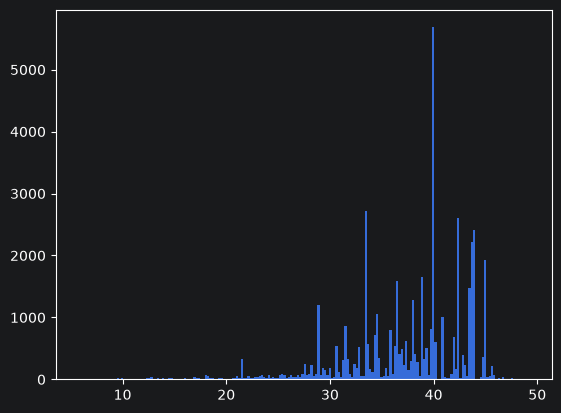

In [8]:
y_test_pred = model.predict(X_test)
plt.hist(y_test_pred[y_test == 60], bins=200)
plt.show()

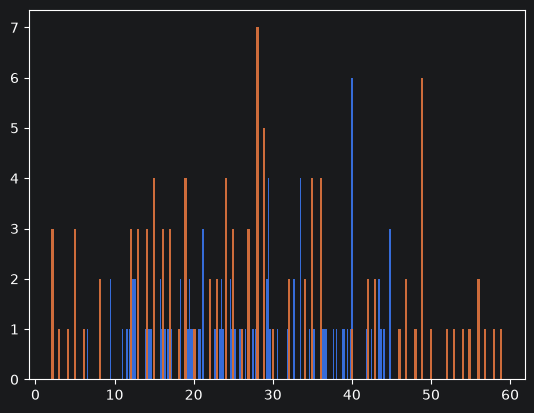

In [9]:
plt.hist(y_test_pred[y_test != 60], bins=200)
plt.hist(y_test[y_test != 60], bins=200)
plt.show()

In [10]:
errors = np.abs(y_test_pred - y_test)
mask_low = (y_test != 60) & (y_test <= 15)
mask_high = (y_test != 60) & (y_test > 15)

print('низкий RUL, средняя ошибка:', errors[mask_low].mean())
print('высокий RUL, средняя ошибка:', errors[mask_high].mean())

низкий RUL, средняя ошибка: 13.63295074303945
высокий RUL, средняя ошибка: 12.338540671707747


In [13]:
print('final CMSE:', xgb_cmse_metric(np.asarray(y_test), y_test_pred))

final CMSE: 541.6212


Comparing the prediction distributions on test and validation, we see a similar pattern: for healthy (non-failed) disks, predictions peak around 40 days, and nearly all of them fall below the 60-day lower bound. Because CMSE specifically penalizes under-prediction on censored disks, this systematic bias inflates the CMSE score without necessarily indicating a proportionally worse model — making MAE the more informative metric here. MAE comes out to about 13 days (~20% of the 60-day window), and it's roughly the same whether the disk actually failed or not.